### 1. Формализация среды (MDP)
Перед началом программирования определим 4 ключевых элемента задачи:
1. **Состояние среды (State):** пара `((v1, v2, v3, v4), lifted_glass)` — текущие целочисленные объемы компота в стаканах и индекс стакана, который агент держит в руке (`-1`, если руки пусты). Запоминание поднятого стакана позволяет корректно начислять штраф за его смену.
2. **Пространство действий (Action):** выбор одного стакана-источника с излишком и распределение компота в один или несколько стаканов с недостатком за один шаг.
3. **Функция награды (Reward):** награда напрямую привязана к цели минимизации поднятий. За смену стакана выдается штраф (`-10` в базовом варианте или `-1` в тесте чувствительности), за продолжение переливания из того же стакана — `-1`, за достижение цели — `+100`.
4. **Терминальное состояние:** достижение равного объема `(4, 4, 4, 4)` во всех стаканах.

### 2. Параметры, генерализация и эталон (BFS)
* **Генерализация (случайный старт):** при обучении среда каждый раз случайно распределяет 16 единиц компота по 4 стаканам (с учетом вместимости `CAPACITY = 8`). Это учит агента универсальной стратегии для любых начальных условий, а не заучиванию одного маршрута.
* **Тестовое состояние и BFS:** для итоговой проверки зафиксировано состояние `(7, 6, 2, 1)`. С помощью классического поиска в ширину (BFS) заранее вычислен математический оптимум — ровно **2 поднятия**.
* **Гиперпараметры:** `EPISODES = 3500` (достаточно для сходимости), `MAX_STEPS = 30` (защита от зацикливания), скорость обучения $\alpha = 0.2$ и коэффициент дисконтирования $\gamma = 1.0$ (так как эпизод всегда конечен).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict, deque
from itertools import product

SEED = 42
CAPACITY = 8
EPISODES = 3500
MAX_STEPS = 30
TEST_STATE = (7, 6, 2, 1)

class CompoteEnv:
    def __init__(self, capacity=CAPACITY, soft_penalty=False, fixed_initial=None):
        self.capacity = int(capacity)
        self.total_vol = 16
        self.target_vol = 4
        self.goal = (self.target_vol,) * 4
        self.soft_penalty = soft_penalty
        self.fixed_initial = fixed_initial
        self.reset()

    def reset(self):
        if self.fixed_initial:
            self.state = tuple(self.fixed_initial)
        else:
            volumes = [0] * 4
            for _ in range(self.total_vol):
                valid_glasses = [i for i in range(4) if volumes[i] < self.capacity]
                volumes[np.random.choice(valid_glasses)] += 1
            self.state = tuple(volumes)

        self.lifted_glass = -1
        return self._get_state_key()

    def _get_state_key(self):
        return (self.state, self.lifted_glass)

    def actions(self, state=None):
        if state is None:
            s = self.state
        elif len(state) == 2 and isinstance(state[1], int):
            s = state[0]
        else:
            s = tuple(state)

        options = []
        for i in range(4):
            surplus = s[i] - self.target_vol
            if surplus <= 0: continue
            receivers = [j for j in range(4) if j != i and s[j] < self.target_vol]
            if not receivers: continue
            bounds = [min(self.target_vol - s[j], self.capacity - s[j]) for j in receivers]
            for quantities in product(*(range(k + 1) for k in bounds)):
                total = sum(quantities)
                if not 1 <= total <= surplus: continue
                d = [0] * 4
                for j, q in zip(receivers, quantities): d[j] = q
                options.append((i, tuple(d)))
        return options

    def step(self, action):
        source, transfers = action
        updated = list(self.state)
        updated[source] -= sum(transfers)
        for j, units in enumerate(transfers):
            updated[j] += units
        self.state = tuple(updated)

        if source == sum(transfers) == 0:
            return self._get_state_key(), -50.0, False

        if self.lifted_glass != source:
            reward = -1.0 if self.soft_penalty else -10.0
            self.lifted_glass = source
        else:
            reward = -1.0

        done = self.state == self.goal
        if done: reward = 100.0

        return self._get_state_key(), reward, done

    def render_action(self, action):
        source, amounts = action
        desc = ', '.join(f'в стакан {j+1}: {amounts[j]}' for j in range(4) if amounts[j])
        return f'поднять стакан {source + 1}; перелить {desc}'

def bfs_optimal(initial=TEST_STATE, capacity=CAPACITY):
    e = CompoteEnv(capacity=capacity, fixed_initial=initial)
    start = e.reset()[0]
    goal = e.goal
    queue = deque([start])
    parents = {start: None}
    moves = {}
    while queue:
        s = queue.popleft()
        if s == goal:
            path = []
            while parents[s] is not None:
                path.append((parents[s], moves[s], s))
                s = parents[s]
            return path[::-1]
        for a in e.actions(s):
            s1 = list(s)
            i, d = a
            s1[i] -= sum(d)
            for j in range(4): s1[j] += d[j]
            s1 = tuple(s1)
            if s1 not in parents:
                parents[s1], moves[s1] = s, a
                queue.append(s1)
    return []

optimal_path = bfs_optimal()

### 3. Обучение агентов (Q-Learning и SARSA)

Для сравнения реализуем два классических табличных метода временных разностей:
* **Q-Learning (Off-policy):** обновляет оценки, ориентируясь на максимально возможную награду в следующем состоянии, игнорируя случайные исследовательские ходы.
* **SARSA (On-policy):** обновляет оценки на основе реально выбранного следующего действия, учитывая риск случайной ошибки во время обучения.

Чтобы провести **анализ чувствительности к функции награды**, дополнительно обучим третьего агента (Q-Learning с мягким штрафом `-1` за смену стакана).

Во всех случаях используется **$\epsilon$-жадная стратегия**: вероятность случайного хода $\epsilon$ плавно снижается с `1.0` до `0.02`, переводя агента от исследования среды к использованию накопленного опыта. Историю изменения $\epsilon$ сохраняем для визуализации.

In [2]:
def epsilon_by_episode(ep, total, start=1.0, end=0.02):
    return start * (end / start) ** (ep / max(total - 1, 1))

def choose_action(Q, state, actions, epsilon, rng):
    if rng.random() < epsilon:
        return actions[int(rng.integers(len(actions)))]
    values = np.array([Q[(state, a)] for a in actions], dtype=float)
    best = np.flatnonzero(np.isclose(values, values.max()))
    return actions[int(rng.choice(best))]

def train_agent(method='q_learning', soft_penalty=False, episodes=EPISODES, seed=SEED):
    rng = np.random.default_rng(seed)
    e = CompoteEnv(soft_penalty=soft_penalty)
    Q = defaultdict(float)
    rewards = []
    epsilons = []

    alpha, gamma = 0.2, 1.0

    for ep in range(episodes):
        s = e.reset()
        total_reward = 0.0
        epsilon = epsilon_by_episode(ep, episodes)
        epsilons.append(epsilon)

        actions = e.actions(s)
        if actions:
            a = choose_action(Q, s, actions, epsilon, rng)

        for _ in range(MAX_STEPS):
            if not actions: break
            s1, r, done = e.step(a)
            next_actions = e.actions(s1)

            if method == 'q_learning':
                future = 0.0 if done or not next_actions else max(Q[(s1, b)] for b in next_actions)
                Q[(s, a)] += alpha * (r + gamma * future - Q[(s, a)])
                if not done and next_actions:
                    a1 = choose_action(Q, s1, next_actions, epsilon, rng)
                else: a1 = None
            elif method == 'sarsa':
                if done or not next_actions:
                    future = 0.0
                    Q[(s, a)] += alpha * (r + gamma * future - Q[(s, a)])
                    a1 = None
                else:
                    a1 = choose_action(Q, s1, next_actions, epsilon, rng)
                    future = Q[(s1, a1)]
                    Q[(s, a)] += alpha * (r + gamma * future - Q[(s, a)])

            s = s1
            a = a1
            actions = next_actions
            total_reward += r
            if done: break

        rewards.append(total_reward)
    return Q, np.array(rewards), np.array(epsilons)

# Q-Learning (Жесткий штраф)
Q_q, rewards_q, eps_history = train_agent(method='q_learning', soft_penalty=False)
# SARSA (Жесткий штраф)
Q_sarsa, rewards_sarsa, _ = train_agent(method='sarsa', soft_penalty=False)
# Q-Learning (Мягкий штраф - анализ чувствительности)
Q_soft, rewards_soft, _ = train_agent(method='q_learning', soft_penalty=True)

### 4. Тестирование стратегий и анализ чувствительности штрафов

После обучения отключаем случайные ходы ($\epsilon = 0$) и запускаем жадную стратегию всех трех агентов на эталонном состоянии `(7, 6, 2, 1)`.

В выводе проверяем два показателя:
1. Совпадает ли число уникальных поднятий стакана с эталоном BFS (2 поднятия).
2. Как размер штрафа за смену стакана (`-10` против `-1`) влияет на саму траекторию переливаний и общее число шагов.

In [3]:
def evaluate_greedy(Q, initial=TEST_STATE, soft_penalty=False):
    e = CompoteEnv(fixed_initial=initial, soft_penalty=soft_penalty)
    s = e.reset()
    history = []

    lifts_count = 0
    current_glass = -1

    for _ in range(MAX_STEPS):
        if s[0] == e.goal: break
        actions = e.actions(s)
        if not actions: break
        a = max(actions, key=lambda x: Q.get((s, x), 0.0))

        source = a[0]
        if source != current_glass:
            lifts_count += 1
            current_glass = source

        s1, reward, done = e.step(a)
        history.append((s[0], a, s1[0]))
        s = s1
        if done: break

    return (s[0] == e.goal), lifts_count, history

print(f"--- РЕЗУЛЬТАТЫ ДЛЯ СТАРТОВОГО СОСТОЯНИЯ {TEST_STATE} ---")
print(f"Эталон BFS: {len(optimal_path)} поднятия(й)\n")

render_env = CompoteEnv()

for name, Q_table, is_soft in [
    ('Q-learning (Жесткий штраф -10)', Q_q, False),
    ('SARSA (Жесткий штраф -10)', Q_sarsa, False),
    ('Q-learning (Мягкий штраф -1)', Q_soft, True)
]:
    success, lifts, history = evaluate_greedy(Q_table, soft_penalty=is_soft)
    print(f"{name}: Успех={success}, Поднятий={lifts}")
    if is_soft or name == 'Q-learning (Жесткий штраф -10)':
        print(f"  Траектория агента '{name}':")
        for k, (s0, a, s1) in enumerate(history, 1):
            print(f"    Шаг {k}: {s0} -> {s1} (Действие: {render_env.render_action(a)})")
    print("-" * 50)

--- РЕЗУЛЬТАТЫ ДЛЯ СТАРТОВОГО СОСТОЯНИЯ (7, 6, 2, 1) ---
Эталон BFS: 2 поднятия(й)

Q-learning (Жесткий штраф -10): Успех=True, Поднятий=2
  Траектория агента 'Q-learning (Жесткий штраф -10)':
    Шаг 1: (7, 6, 2, 1) -> (4, 6, 2, 4) (Действие: поднять стакан 1; перелить в стакан 4: 3)
    Шаг 2: (4, 6, 2, 4) -> (4, 5, 3, 4) (Действие: поднять стакан 2; перелить в стакан 3: 1)
    Шаг 3: (4, 5, 3, 4) -> (4, 4, 4, 4) (Действие: поднять стакан 2; перелить в стакан 3: 1)
--------------------------------------------------
SARSA (Жесткий штраф -10): Успех=True, Поднятий=2
--------------------------------------------------
Q-learning (Мягкий штраф -1): Успех=True, Поднятий=2
  Траектория агента 'Q-learning (Мягкий штраф -1)':
    Шаг 1: (7, 6, 2, 1) -> (6, 6, 2, 2) (Действие: поднять стакан 1; перелить в стакан 4: 1)
    Шаг 2: (6, 6, 2, 2) -> (5, 6, 2, 3) (Действие: поднять стакан 1; перелить в стакан 4: 1)
    Шаг 3: (5, 6, 2, 3) -> (4, 6, 2, 4) (Действие: поднять стакан 1; перелить в стака

### 5. Визуализация кривых обучения и выводы

На графике ниже показаны сглаженные кривые суммарной награды (левая ось) и динамика затухания параметра $\epsilon$ (правая ось, красный пунктир).

**Основные выводы по результатам экспериментов:**
1. **Сравнение Q-Learning и SARSA:** при обучении на случайных стартовых состояниях оба метода (с жестким штрафом `-10`) показывают схожую динамику, удерживая среднюю награду в диапазоне `88–92`, и при тестировании оба находят оптимальное решение за 2 поднятия. В детерминированной среде оба алгоритма справляются с задачей, но Q-Learning остается предпочтительным за счет более простой логики обновления (Off-policy) без учета риска случайных ошибок.
2. **Влияние штрафов (анализ чувствительности):** оба варианта Q-Learning достигли оптимума по числу поднятий (2 поднятия, как в эталоне BFS). Однако агент с жестким штрафом (`-10`) сработал эффективнее: он уложился в **3 шага**, сразу перелив 3 единицы на первом ходе. Агент с мягким штрафом (`-1`) растянул решение на **5 шагов**, переливая по 1 единице за раз. При этом его кривая на графике расположена выше (`95–99`) не из-за лучшего качества стратегии, а из-за меньшего размера самого штрафа.
3. **Затухание исследования и колебания графика:** по мере снижения $\epsilon$ к `0.02` алгоритмы стабилизируются, но на графике сохраняются умеренные колебания. Это естественное следствие генерализации среды: каждый эпизод начинается со случайного распределения компота, для которого минимально возможное число поднятий (а значит, и максимальная награда) отличается от эпизода к эпизоду.

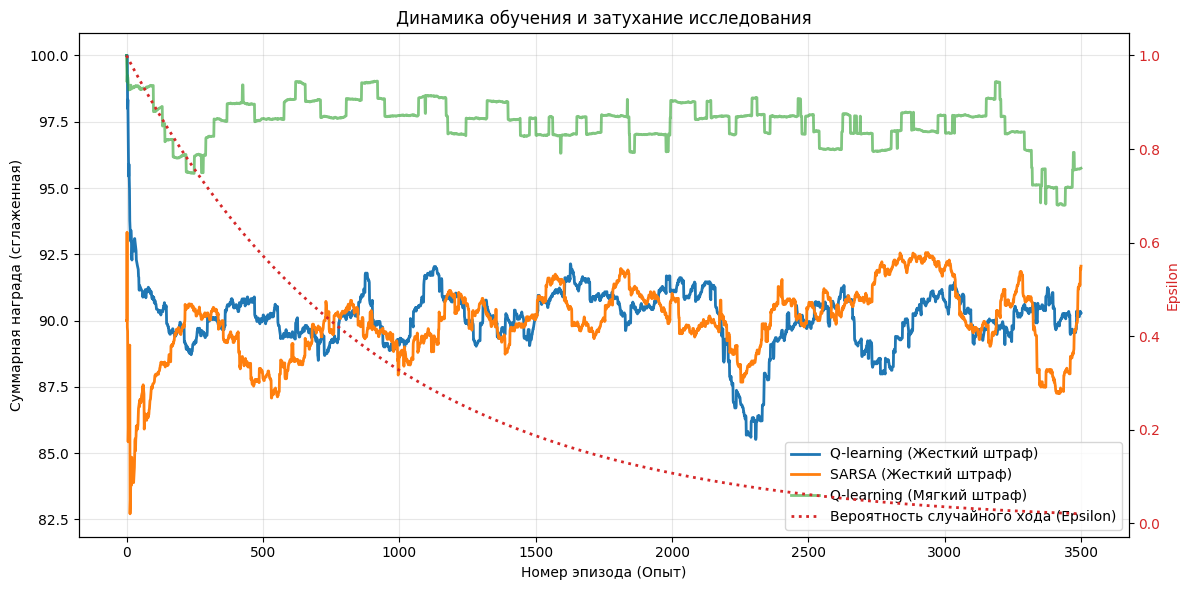

In [4]:
def smooth(y, window=150):
    y = np.asarray(y, dtype=float)
    result = np.empty_like(y)
    csum = np.concatenate(([0.], np.cumsum(y)))
    for i in range(len(y)):
        start = max(0, i - window + 1)
        result[i] = (csum[i+1] - csum[start]) / (i+1-start)
    return result

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(smooth(rewards_q), label='Q-learning (Жесткий штраф)', linewidth=2, color='tab:blue')
ax1.plot(smooth(rewards_sarsa), label='SARSA (Жесткий штраф)', linewidth=2, color='tab:orange')
ax1.plot(smooth(rewards_soft), label='Q-learning (Мягкий штраф)', linewidth=2, color='tab:green', alpha=0.6)

ax1.set_xlabel('Номер эпизода (Опыт)')
ax1.set_ylabel('Суммарная награда (сглаженная)', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(eps_history, color='tab:red', linestyle=':', linewidth=2, label='Вероятность случайного хода (Epsilon)')
ax2.set_ylabel('Epsilon', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')

plt.title('Динамика обучения и затухание исследования')
fig.tight_layout()
plt.show()